<a href="https://colab.research.google.com/github/jalmendral/BA305-A1-TeamA2/blob/main/Classification_Regression_RandomForest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Recipe ratings using decision trees and random forests
**Kenny Li — BA305**

**Question: Can we predict a recipe's average rating from its ingredients?**


## 1. Load libraries
These are the same main tools as the class lab, plus text encoding, a baseline, and a few evaluation metrics.

In [31]:
# Load tools for tables, numbers, graphs, and models.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn import tree
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")


## 2. Load and inspect the recipes

In [32]:
# Read the cleaned recipe dataset from the GitHub repository.
url = "https://raw.githubusercontent.com/jalmendral/BA305-A1-TeamA2/main/Data/processed/recipes_clean.csv"
df = pd.read_csv(url)
print("Rows and columns:", df.shape)
display(df.head())


Rows and columns: (15589, 23)


,name,url,author,date_published,ingredients,calories,fat,carbs,protein,avg_rating,...,cook_time,total_time,servings,country,has_cuisine,year,nutrition_flag,time_flag,rating_missing,nutrition_missing
0,Chewy Whole Wheat Peanut Butter Brownies,https://www.allrecipes.com/recipe/140717/chewy...,DMOMMY,2020-06-18,"⅓ cup margarine, softened, ⅔ cup white sugar, ...",222.0,13.0,24.0,6.0,4.4,...,35.0,55.0,16.0,NaN,False,2020,False,False,False,False
1,Pumpkin Pie Eggnog,https://www.allrecipes.com/recipe/269204/pumpk...,Bobbie Susan,2022-09-26,"12 egg yolks, 2 cups heavy whipping cream, ½ ...",477.0,31.0,43.0,8.0,5.0,...,5.0,495.0,8.0,NaN,False,2022,False,False,False,False
2,Eggs Poached in Tomato Sauce,https://www.allrecipes.com/recipe/238054/eggs-...,Bren,2018-06-08,"2 tablespoons olive oil, or to taste, ½ onion...",354.0,18.0,32.0,20.0,4.8,...,75.0,85.0,4.0,NaN,False,2018,False,False,False,False
3,Minestrone Casserole,https://www.allrecipes.com/minestrone-casserol...,Sarah Brekke,2025-03-03,4 cups dried mafalda pasta (mini lasagna noodl...,356.0,9.0,53.0,19.0,4.3,...,40.0,60.0,8.0,NaN,False,2025,False,False,False,False
4,Yummy Stuffed Peppers,https://www.allrecipes.com/recipe/241937/yummy...,Procrastigirl,2024-12-11,"4 green bell peppers, halved lengthwise and se...",366.0,22.0,23.0,19.0,4.7,...,95.0,125.0,8.0,NaN,False,2024,False,False,False,False


In [33]:
# Check the variables needed for this project.
print(df.columns.tolist())
display(df[["ingredients", "avg_rating", "total_ratings"]].isna().sum())


['name', 'url', 'author', 'date_published', 'ingredients', 'calories', 'fat', 'carbs', 'protein', 'avg_rating', 'total_ratings', 'reviews', 'prep_time', 'cook_time', 'total_time', 'servings', 'country', 'has_cuisine', 'year', 'nutrition_flag', 'time_flag', 'rating_missing', 'nutrition_missing']


,0
ingredients,10
avg_rating,1030
total_ratings,1030


## 3. Clean the modeling data
We need ingredient text and an observed rating. Review counts are kept only to investigate errors; they are not predictors.

In [34]:
# Convert ratings to numbers and remove missing inputs or targets.
model_df = df.copy()
model_df["avg_rating"] = pd.to_numeric(model_df["avg_rating"], errors="coerce")
model_df = model_df.dropna(subset=["ingredients", "avg_rating"])
model_df = model_df[model_df["ingredients"].str.strip() != ""]
model_df = model_df[model_df["avg_rating"].between(1, 5)]

# Avoid putting copies of the same recipe into different data splits.
model_df = model_df.drop_duplicates(subset="url")
model_df["ingredient_key"] = model_df["ingredients"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
model_df = model_df.drop_duplicates(subset="ingredient_key").reset_index(drop=True)

print("Recipes available:", len(model_df))
X = model_df["ingredients"]
y = model_df["avg_rating"]


Recipes available: 14555


This removes exact repeated ingredient texts, not every near-duplicate recipe. The results describe recipes that already have ratings; unrated recipes may behave differently.

## 4. Split the data
The outer split stays 80% training and 20% testing with `random_state=42`. We hold back part of training for checking errors and choosing a decision threshold. Grid search uses only the fitting subset.

In [35]:
# Keep 20% completely separate for final evaluation.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Reserve 20% of the training portion for validation.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42)

print("Fitting recipes:", len(X_fit))
print("Validation recipes:", len(X_val))
print("Test recipes:", len(X_test))


Fitting recipes: 9315
Validation recipes: 2329
Test recipes: 2911


## 5. Start with the charts
Use fitting data for exploration. A high average rating alone does not mean ingredients can predict ratings.

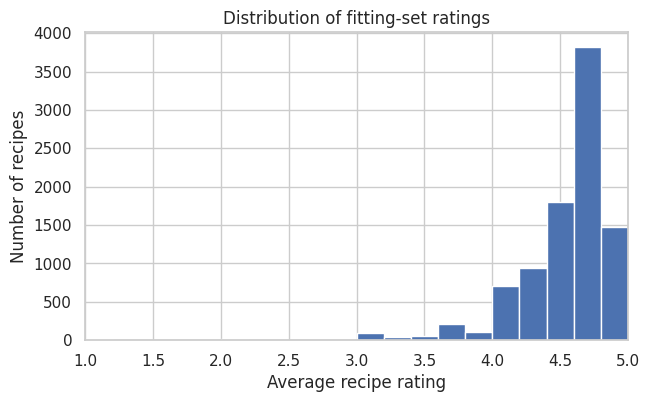

,avg_rating
count,9315.000000
mean,4.521267
std,0.413317
min,1.000000
25%,4.400000
50%,4.600000
75%,4.800000
max,5.000000


In [36]:
# See whether ratings are concentrated near the top of the scale.
plt.figure(figsize=(7, 4))
plt.hist(y_fit, bins=np.linspace(1, 5, 21), edgecolor="white")
plt.xlabel("Average recipe rating")
plt.ylabel("Number of recipes")
plt.title("Distribution of fitting-set ratings")
plt.xlim(1, 5)
plt.show()
display(y_fit.describe())


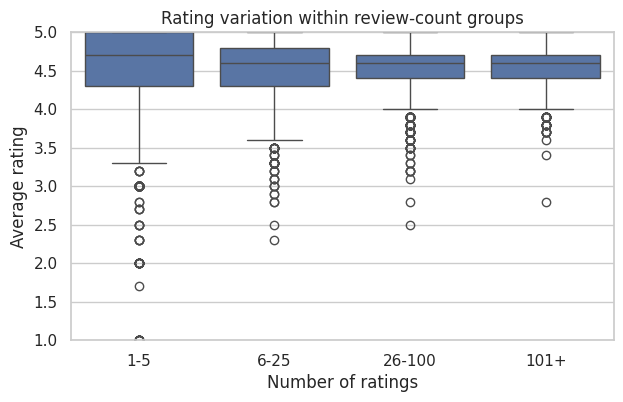

,count,mean,std
review_group,,,
1-5,2539,4.514533,0.627400
6-25,2157,4.509040,0.368604
26-100,2244,4.507620,0.285135
101+,2375,4.552463,0.218773


In [37]:
# Check the spread of ratings within review-count groups.
eda = model_df.loc[X_fit.index].copy()
eda["review_group"] = pd.cut(eda["total_ratings"], bins=[0, 5, 25, 100, np.inf],
                            labels=["1-5", "6-25", "26-100", "101+"])
plt.figure(figsize=(7, 4))
sns.boxplot(data=eda, x="review_group", y="avg_rating")
plt.xlabel("Number of ratings")
plt.ylabel("Average rating")
plt.ylim(1, 5)
plt.title("Rating variation within review-count groups")
plt.show()

# Compare means with spread, rather than showing means alone.
display(eda.groupby("review_group", observed=True)["avg_rating"].agg(["count", "mean", "std"]))


**Explain the charts:** Are most ratings high? Does the group with few ratings have more spread? A wide spread does not prove the reviews are wrong. It suggests the target can be more variable in that group.

## 6. Convert ingredient text into model inputs
Each retained word or phrase becomes a 0/1 indicator. For example, `milk=1` means milk is mentioned. We keep phrases such as “olive oil,” but this is not a perfect ingredient parser. Quantities are excluded, and some preparation words remain.

`Pipeline` makes sure the vocabulary is learned only from the data being used to train each model. The words `text` and `model` are names for its two steps. Later, `model__max_depth` means the `max_depth` setting inside the model step.

In [38]:
# Remove common measurement/preparation words while keeping ingredient words.
stop_words = "cup cups tablespoon tablespoons teaspoon teaspoons ounce ounces pound pounds gram grams kilogram kilograms package packages can cans pinch taste needed optional chopped diced minced sliced divided softened fresh freshly large small medium and or of to for with as such into the a an".split()

# Turn ingredient text into indicators for up to 2,000 words and phrases.
vectorizer = CountVectorizer(
    binary=True,
    lowercase=True,
    stop_words=stop_words,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b",
    ngram_range=(1, 2),
    min_df=5,
    max_features=2000
)


## 7. Establish the baseline
**Primary metric: RMSE.** Ratings are numbers, and squared errors give larger misses more weight. RMSE is measured in rating points; lower is better. A mean-predicting dummy is the appropriate constant baseline for this metric. MAE and R² are supporting measures.

The dummy uses a column of zeros because it must receive an input array even though it ignores inputs.

In [39]:
# Predict the fitting-set mean for every recipe, without using ingredients.
dummy = DummyRegressor(strategy="mean")
dummy.fit(np.zeros((len(X_fit), 1)), y_fit)

# With cv=3, the baseline and regressors use the same three folds.
dummy_scores = cross_val_score(
    DummyRegressor(strategy="mean"), np.zeros((len(X_fit), 1)), y_fit,
    cv=3, scoring="neg_root_mean_squared_error")
dummy_cv_rmse = -dummy_scores.mean()
print("Mean rating prediction:", round(y_fit.mean(), 4))
print("Baseline CV RMSE:", round(dummy_cv_rmse, 4))


Mean rating prediction: 4.5213
Baseline CV RMSE: 0.4133


## 8. Fit a full regression tree
Like the lab's full classification tree, this tree has no explicit depth or leaf-size restriction. For regression, a split tries to reduce squared error, and a leaf predicts the mean rating of its training recipes.

In [40]:
# First convert the text, then grow a full tree.
full_tree = Pipeline([
    ("text", vectorizer),
    ("model", DecisionTreeRegressor(random_state=42))
])
full_tree.fit(X_fit, y_fit)

print("Actual depth:", full_tree.named_steps["model"].get_depth())
print("Number of leaves:", full_tree.named_steps["model"].get_n_leaves())
print("Number of nodes:", full_tree.named_steps["model"].tree_.node_count)


Actual depth: 240
Number of leaves: 6799
Number of nodes: 13597


In [41]:
# Compare familiar training recipes with unseen validation recipes.
full_train_pred = full_tree.predict(X_fit)
full_val_pred = full_tree.predict(X_val)
print("Full tree train RMSE:", np.sqrt(mean_squared_error(y_fit, full_train_pred)))
print("Full tree validation RMSE:", np.sqrt(mean_squared_error(y_val, full_val_pred)))


Full tree train RMSE: 0.009580576162920814
Full tree validation RMSE: 0.5510694547970381


**Question:** Is training error much lower than validation error? That is evidence of overfitting. A full tree does not necessarily have zero regression error if different recipes share identical input features.

## 9. Fit and visualize a reduced tree
These settings are an illustration, not the final selected model. Depth limits the number of splits along a path; minimum leaf size limits how small each final group can become.

In [42]:
# Restrict tree growth, following the reduced-tree example in the lab.
reduced_tree = Pipeline([
    ("text", vectorizer),
    ("model", DecisionTreeRegressor(max_depth=3, min_samples_leaf=40, random_state=42))
])
reduced_tree.fit(X_fit, y_fit)

print("Reduced tree train RMSE:", np.sqrt(mean_squared_error(y_fit, reduced_tree.predict(X_fit))))
print("Reduced tree validation RMSE:", np.sqrt(mean_squared_error(y_val, reduced_tree.predict(X_val))))


Reduced tree train RMSE: 0.4098016172823937
Reduced tree validation RMSE: 0.3986904301013467


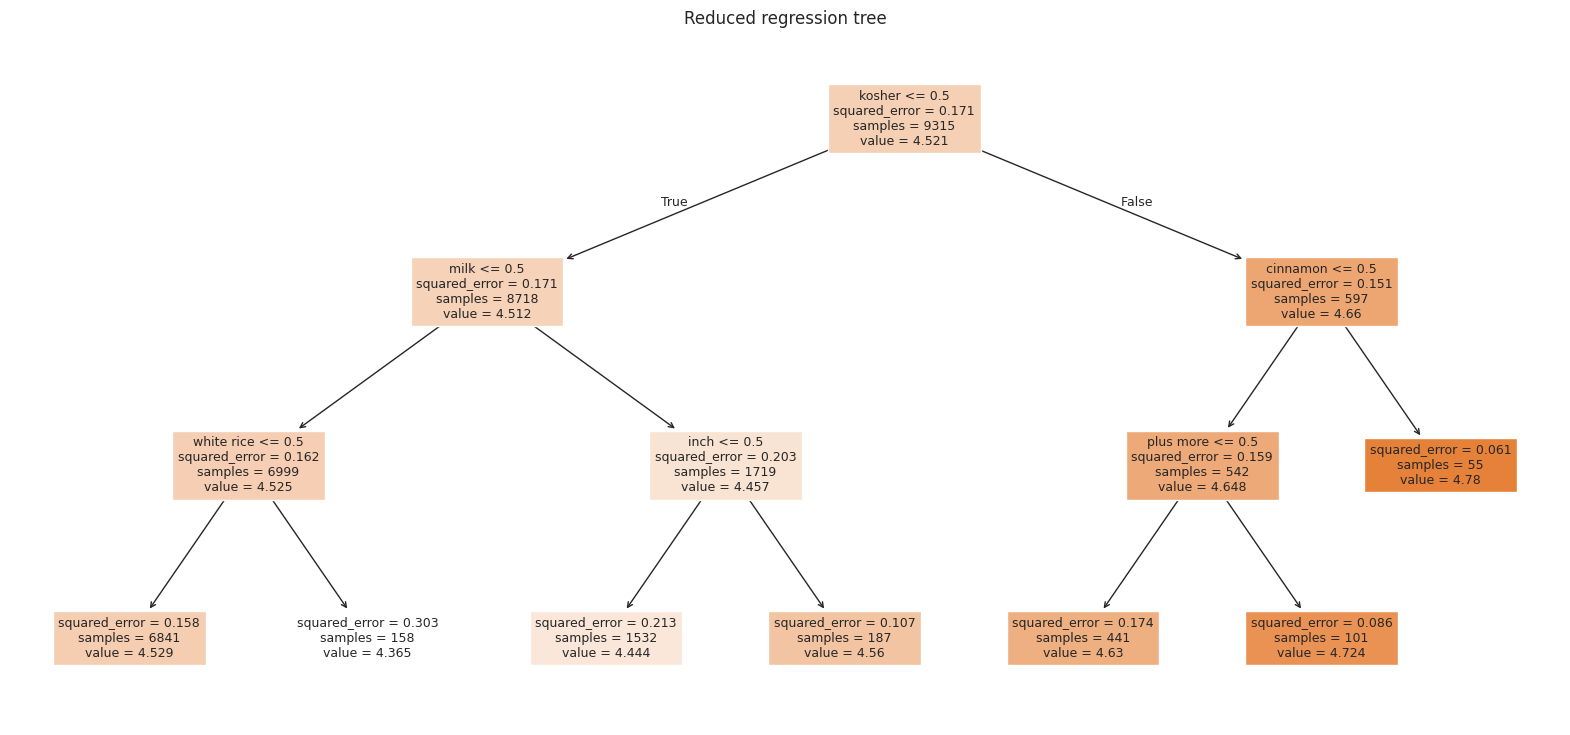

In [43]:
# Plot the small tree just like the lab. Each value is a predicted rating.
plt.figure(figsize=(20, 9))
tree.plot_tree(
    reduced_tree.named_steps["model"],
    feature_names=reduced_tree.named_steps["text"].get_feature_names_out(),
    filled=True, fontsize=9
)
plt.title("Reduced regression tree")
plt.show()


For a binary ingredient feature, `milk <= 0.5` means milk is absent: go left. If present, go right. `samples` is the number of fitting recipes at the node; `value` is their mean rating. The tree selects its splits automatically. We set limits, not the exact number of leaves.

## 10. Tune the regression tree with grid search
This is the lab's `GridSearchCV` approach. We test six depth values and seven minimum leaf sizes: 42 combinations × 3 folds = 126 fits. Higher negative RMSE means lower error. Three folds keep runtime manageable.

**This cell takes time.** Progress is printed. There is no automatic restart or expansion loop.

In [44]:
# Tune two hyperparameters while keeping all other settings fixed.
param_grid = {
    "model__max_depth": [1, 3, 6, 12, 24, None],
    "model__min_samples_leaf": [1, 5, 15, 40, 100, 300, 900]
}

tree_grid = GridSearchCV(
    Pipeline([("text", vectorizer), ("model", DecisionTreeRegressor(random_state=42))]),
    param_grid, cv=3, scoring="neg_root_mean_squared_error",
    n_jobs=2, verbose=2
)
tree_grid.fit(X_fit, y_fit)
best_tree = tree_grid.best_estimator_
print("Best tree settings:", tree_grid.best_params_)
print("Best tree CV RMSE:", -tree_grid.best_score_)


Fitting 3 folds for each of 42 candidates, totalling 126 fits
Best tree settings: {'model__max_depth': 6, 'model__min_samples_leaf': 300}
Best tree CV RMSE: 0.4111843430169861


## 11. Tune a random forest
Each tree sees a bootstrap sample and a random subset of candidate features at splits. The forest averages tree predictions. We fix the forest at **50 trees** to reduce runtime and tune the same two growth limits as the regression tree.

**This is the longest regression cell.** Changing the number of trees does not change your data split.

In [45]:
# Fit many trees, average their predictions, and select the best growth limits.
forest_grid = GridSearchCV(
    Pipeline([
        ("text", vectorizer),
        ("model", RandomForestRegressor(
            n_estimators=50, max_features=0.5, random_state=42, n_jobs=1))
    ]),
    param_grid, cv=3, scoring="neg_root_mean_squared_error",
    n_jobs=2, verbose=2
)
forest_grid.fit(X_fit, y_fit)
best_forest = forest_grid.best_estimator_
print("Best forest settings:", forest_grid.best_params_)
print("Best forest CV RMSE:", -forest_grid.best_score_)


Fitting 3 folds for each of 42 candidates, totalling 126 fits
Best forest settings: {'model__max_depth': 24, 'model__min_samples_leaf': 40}
Best forest CV RMSE: 0.4071135072023521


**Check the search boundaries before continuing.** If a selected minimum leaf size is 900, add 1800 and 3600 to the grid above and rerun the two search cells. The project asks you to widen a range when its edge wins. A leaf size of 1 and depth of 1 are natural lower limits; depth `None` already permits unlimited depth. The earlier experiment selected leaf sizes of 300 and 15, but this notebook must use its own output.

## 12. Compare fit and choose a regression method
Choose using CV, not the final test score. The short loop below repeats the same calculation for two named models; it is not another tuning search.

,Model,Train RMSE,CV RMSE
0,Mean baseline,0.4133,0.4133
1,Regression tree,0.4088,0.4112
2,Random forest,0.3935,0.4071


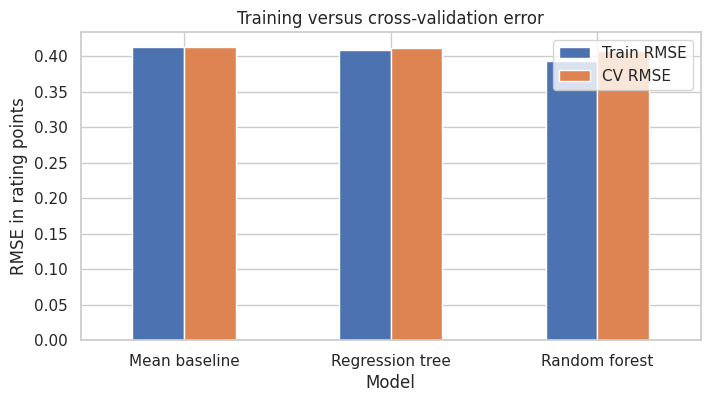

Selected regression method: Random forest


In [46]:
# Put training and CV errors side by side.
fit_rows = [["Mean baseline", np.sqrt(mean_squared_error(
    y_fit, dummy.predict(np.zeros((len(X_fit), 1))))), dummy_cv_rmse]]

for name, search in [("Regression tree", tree_grid), ("Random forest", forest_grid)]:
    train_rmse = np.sqrt(mean_squared_error(y_fit, search.predict(X_fit)))
    fit_rows.append([name, train_rmse, -search.best_score_])

fit_results = pd.DataFrame(fit_rows, columns=["Model", "Train RMSE", "CV RMSE"])
display(fit_results.round(4))
fit_results.set_index("Model").plot.bar(figsize=(8, 4), rot=0)
plt.ylabel("RMSE in rating points")
plt.title("Training versus cross-validation error")
plt.show()

if tree_grid.best_score_ >= forest_grid.best_score_:
    best_model = best_tree
    best_name = "Regression tree"
else:
    best_model = best_forest
    best_name = "Random forest"
print("Selected regression method:", best_name)


**Interpretation:** A large train/CV gap suggests overfitting. Similar errors near the dummy can indicate weak ingredient signal or underfitting; the gap alone cannot tell which. Similar errors meaningfully below the dummy are more encouraging. If neither model improves on the dummy, do not recommend the model just because it is more complicated.

## 13. Read a tree and predict one new recipe
This parallels predicting Isabel's loan acceptance in the lab. The plotted tree is the tuned regression tree, even if the forest wins.

Actual depth: 6
Actual number of leaves: 15


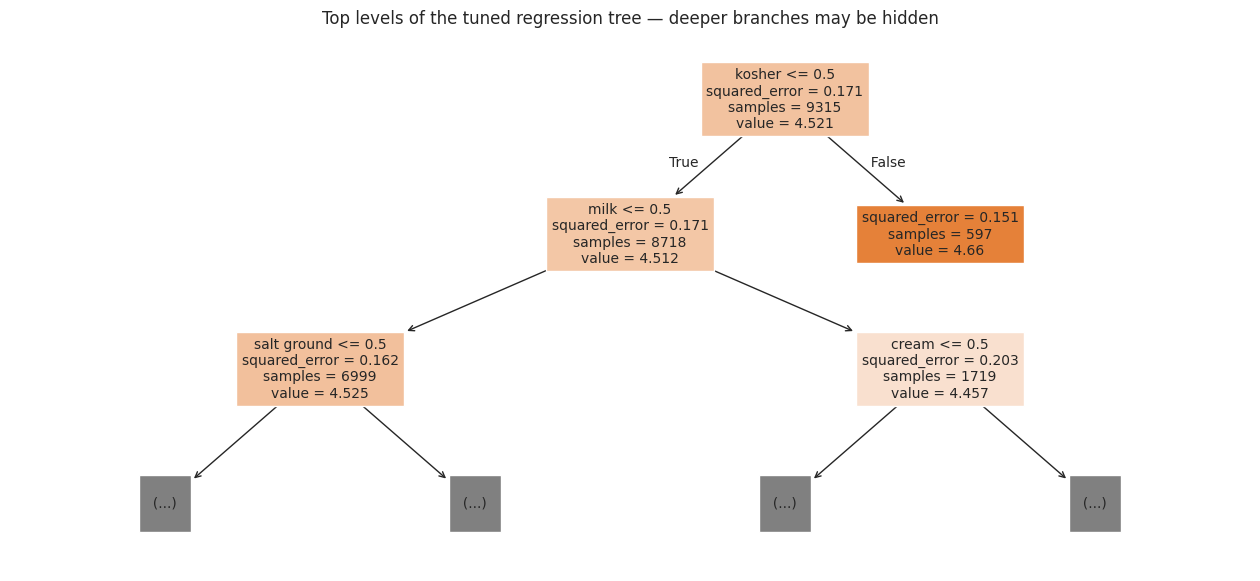

Tree prediction: 4.538025751072975
Forest prediction: 4.530204547762961


In [47]:
# Show only the top two split levels of the selected tree so it remains readable.
print("Actual depth:", best_tree.named_steps["model"].get_depth())
print("Actual number of leaves:", best_tree.named_steps["model"].get_n_leaves())
plt.figure(figsize=(16, 7))
tree.plot_tree(best_tree.named_steps["model"],
               feature_names=best_tree.named_steps["text"].get_feature_names_out(),
               max_depth=2, filled=True, fontsize=10)
plt.title("Top levels of the tuned regression tree — deeper branches may be hidden")
plt.show()

# Example only: we do not know this new recipe's actual rating.
new_recipe = pd.Series(["chicken breast, olive oil, garlic, salt, black pepper"])
print("Tree prediction:", best_tree.predict(new_recipe)[0])
print("Forest prediction:", best_forest.predict(new_recipe)[0])


## 14. Diagnose errors using validation recipes
Residual = actual minus predicted. Positive residual means underprediction. Absolute error measures the size of a miss, regardless of direction.

In [48]:
# Match each validation prediction with its recipe and observed rating.
errors = model_df.loc[X_val.index, ["name", "ingredients", "total_ratings"]].copy()
errors["Actual"] = y_val
errors["Predicted"] = best_model.predict(X_val)
errors["Absolute error"] = abs(errors["Actual"] - errors["Predicted"])

# A familiar-recipe check, then difficult cases and easy cases.
display(errors[errors["name"].str.contains("chicken|brownie", case=False, na=False)].head(5))
print("Largest misses:")
display(errors.nlargest(5, "Absolute error"))
print("Smallest misses:")
display(errors.nsmallest(5, "Absolute error"))


,name,ingredients,total_ratings,Actual,Predicted,Absolute error
6809,Tortellini Alfredo with Grilled Chicken Breasts,"2 large skinless, boneless chicken breasts, 2 ...",4.0,4.3,4.687473,0.387473
4142,Teriyaki and Pineapple Chicken,"2 tablespoons vegetable oil, 1 pound skinless,...",325.0,4.4,4.389748,0.010252
10327,Teriyaki Chicken with Mushrooms and Broccoli,"½ cup soy sauce, ½ cup rice vinegar, 3 tablesp...",22.0,4.0,4.490031,0.490031
10321,Easy Tex-Mex Chicken Tacos,"4 cups water, 1 (16 ounce) package yellow rice...",3.0,4.3,4.493934,0.193934
4670,Low-Fat Chicken Pot Pie,"3 bone-in chicken breast halves, skin removed,...",168.0,4.5,4.436435,0.063565


Largest misses:


,name,ingredients,total_ratings,Actual,Predicted,Absolute error
8379,Air Fryer Samosas,"12 ounces yukon gold potatoes, peeled and cut ...",1.0,1.0,4.551898,3.551898
7327,Mango and White Chocolate Mousse Cake,"3 ounces white chocolate, 3 tablespoons heavy ...",1.0,1.0,4.539323,3.539323
5873,Pumpkin Pie with Truvia® Natural Sweetener,"pastry for a single-crust 9-inch pie, 1 (16 ou...",1.0,2.0,4.576825,2.576825
11593,Coffee-Rubbed Steak,"1/4 cup finely ground coffee, 2 tablespoons da...",1.0,2.0,4.509741,2.509741
7639,One-Pan Oven Mac and Cheese,"½ (8 ounce) package fontina cheese, ½ (8 ounce...",6.0,2.3,4.509257,2.209257


Smallest misses:


,name,ingredients,total_ratings,Actual,Predicted,Absolute error
6294,Banana Cream Pie,"¾ cup white sugar, ⅓ cup all-purpose flour, ¼ ...",1.0,4.5,4.500272,0.000272
9153,Lavender Shortbread Cookies,"1 ½ cups butter, softened, ⅔ cup white sugar, ...",112.0,4.5,4.499261,0.000739
11804,Hearty Italian Lentil Soup,"1 cup lentils, 1 ⅓ quarts water, divided, ⅔ cu...",20.0,4.4,4.399235,0.000765
2838,Peanut Butter Fudge,"¾ cup evaporated milk, 2 cups sugar, 2 tablesp...",159.0,4.4,4.399203,0.000797
7296,Nana's Mashed Turnip,"1 large turnip, peeled and cubed, 3 white pot...",112.0,4.5,4.498927,0.001073


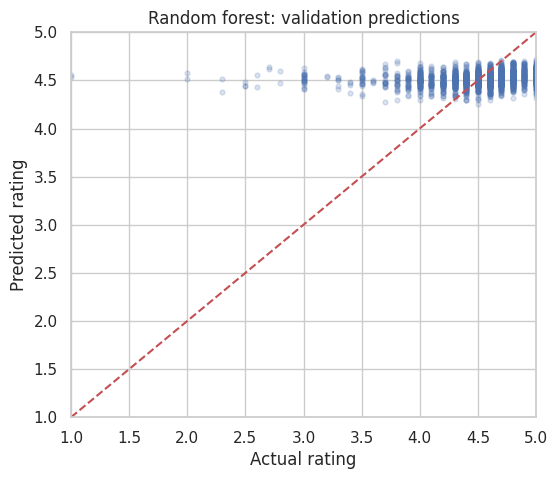

In [49]:
# Perfect predictions would lie on the diagonal line.
plt.figure(figsize=(6, 5))
plt.scatter(errors["Actual"], errors["Predicted"], alpha=0.2, s=12)
plt.plot([1, 5], [1, 5], "r--")
plt.xlabel("Actual rating")
plt.ylabel("Predicted rating")
plt.xlim(1, 5)
plt.ylim(1, 5)
plt.title(best_name + ": validation predictions")
plt.show()


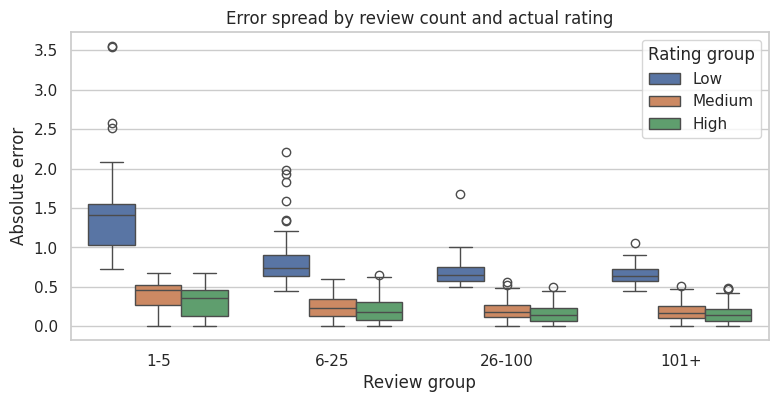

count      mean    median
Review group Rating group                           
1-5          Low              62  1.405465  1.413226
             Medium          122  0.399460  0.461201
             High            382  0.303774  0.352801
6-25         Low              58  0.862443  0.740971
             Medium          160  0.253544  0.235304
             High            366  0.208499  0.185878
26-100       Low              22  0.719406  0.649344
             Medium          157  0.206746  0.183264
             High            390  0.156369  0.139037
101+         Low              11  0.678827  0.640037
             Medium          142  0.183363  0.165124
             High            457  0.149888  0.140346

In [50]:
# Check review volume, then see whether the pattern survives within rating groups.
errors["Review group"] = pd.cut(errors["total_ratings"], [0, 5, 25, 100, np.inf],
                                labels=["1-5", "6-25", "26-100", "101+"])
errors["Rating group"] = pd.cut(errors["Actual"], [0, 4, 4.5, 5.1],
                                right=False, labels=["Low", "Medium", "High"])
plt.figure(figsize=(9, 4))
sns.boxplot(data=errors, x="Review group", y="Absolute error", hue="Rating group")
plt.title("Error spread by review count and actual rating")
plt.show()
display(errors.groupby(["Review group", "Rating group"], observed=True)["Absolute error"].agg(["count", "mean", "median"]))


**Write your findings:** Name one close prediction and one large miss. Are low ratings harder? Are ratings based on few reviews harder even within a rating group? Mention small subgroup counts. If the current features omit the likely explanation, suggest better ingredient parsing or a future broader recipe-information model. Do not claim a causal explanation from these charts or silently remove difficult test cases.

## 15. Choose a simple decision rule
Suppose a recipe site promotes recipes expected to be good. Define good as an actual rating ≥4.5. Assume +$2 for promoting a good recipe, −$5 for promoting a lower-rated recipe, −$1 for skipping a good recipe, and $0 for skipping a lower-rated one. These are **illustrative values, not actual revenue**.

We choose a predicted-rating cutoff on validation data before the final test. This loop is a simple threshold sweep, not another model-fitting step.

In [51]:
# Find the cutoff with the highest assumed value on validation recipes.
validation_predictions = best_model.predict(X_val)
good_validation = y_val.to_numpy() >= 4.5
threshold_rows = []

# 0 promotes everyone; 5.1 promotes no one. Other cutoffs are spaced by 0.05.
for threshold in [0] + list(np.arange(4.0, 5.01, 0.05)) + [5.1]:
    promote = validation_predictions >= threshold
    good_promoted = np.sum(promote & good_validation)
    poor_promoted = np.sum(promote & ~good_validation)
    good_skipped = np.sum(~promote & good_validation)
    value = 2 * good_promoted - 5 * poor_promoted - good_skipped
    threshold_rows.append([threshold, value])

threshold_results = pd.DataFrame(threshold_rows, columns=["Threshold", "Validation value"])
best_threshold = threshold_results.loc[threshold_results["Validation value"].idxmax(), "Threshold"]
print("Chosen predicted-rating cutoff:", round(best_threshold, 2))
display(threshold_results.sort_values("Validation value", ascending=False).head())


Chosen predicted-rating cutoff: 4.45


,Threshold,Validation value
10,4.45,-242
11,4.50,-250
9,4.40,-356
8,4.35,-407
7,4.30,-459


## 16. Final regression comparison on the same test set
Run this after choosing the models and cutoff. RMSE and MAE are errors in rating points, not accuracy percentages. R² describes performance relative to predicting the test-set mean; it can be negative.

In [52]:
# Evaluate the baseline, tree, and forest on identical test recipes.
test_predictions = {
    "Mean baseline": dummy.predict(np.zeros((len(X_test), 1))),
    "Regression tree": best_tree.predict(X_test),
    "Random forest": best_forest.predict(X_test)
}
test_rows = []
for name, predictions in test_predictions.items():
    test_rows.append([name,
        np.sqrt(mean_squared_error(y_test, predictions)),
        mean_absolute_error(y_test, predictions),
        r2_score(y_test, predictions)])

test_results = pd.DataFrame(test_rows, columns=["Model", "Test RMSE", "Test MAE", "Test R2"])
baseline_rmse = test_results.loc[0, "Test RMSE"]
test_results["RMSE improvement (%)"] = 100 * (1 - test_results["Test RMSE"] / baseline_rmse)
display(test_results.round(4))
print("Method selected before testing:", best_name)


,Model,Test RMSE,Test MAE,Test R2,RMSE improvement (%)
0,Mean baseline,0.4139,0.2829,-0.0000,0.0000
1,Regression tree,0.4128,0.2807,0.0053,0.2657
2,Random forest,0.4092,0.2759,0.0226,1.1389


Method selected before testing: Random forest


In [53]:
# Evaluate the frozen decision rule against two policies that ignore ingredients.
good_test = y_test.to_numpy() >= 4.5
policies = {
    "Chosen cutoff": best_model.predict(X_test) >= best_threshold,
    "Promote everyone": np.ones(len(X_test), dtype=bool),
    "Promote no one": np.zeros(len(X_test), dtype=bool)
}
policy_rows = []
for name, promote in policies.items():
    good_promoted = np.sum(promote & good_test)
    poor_promoted = np.sum(promote & ~good_test)
    good_skipped = np.sum(~promote & good_test)
    value = 2 * good_promoted - 5 * poor_promoted - good_skipped
    policy_rows.append([name, good_promoted, poor_promoted, good_skipped, value])

display(pd.DataFrame(policy_rows, columns=["Policy", "Good promoted", "Poor promoted", "Good skipped", "Assumed total value"]))


,Policy,Good promoted,Poor promoted,Good skipped,Assumed total value
0,Chosen cutoff,1723,759,243,-592
1,Promote everyone,1966,945,0,-793
2,Promote no one,0,0,1966,-1966


The highest value is best under the assumed costs. A less-negative value is an improvement, not proof of profit. Do not adjust the cutoff after seeing test outcomes. If simple policies perform similarly, discuss whether the model is worth its complexity.

## 17. Feature importance like the lab
These importances describe which text features reduced training impurity. They do not indicate whether an ingredient increases or decreases ratings, and they do not show causation.

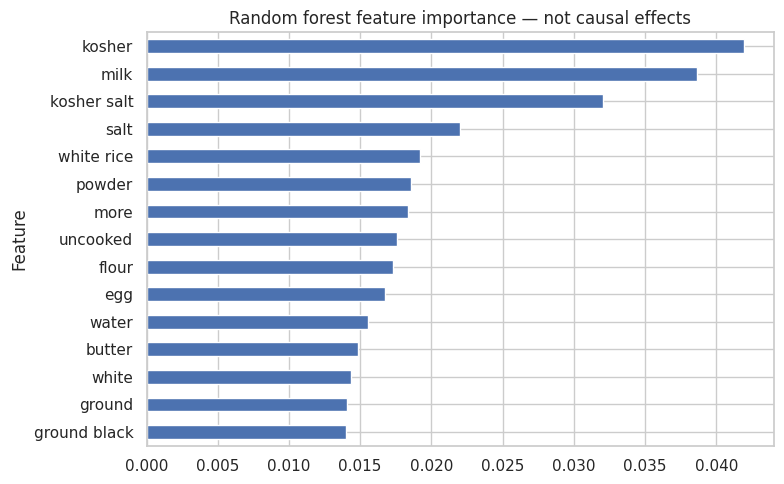

In [54]:
# Rank the forest's ingredient-text features.
importance_df = pd.DataFrame({
    "Feature": best_forest.named_steps["text"].get_feature_names_out(),
    "Importance": best_forest.named_steps["model"].feature_importances_
}).sort_values("Importance", ascending=False)

importance_df.head(15).sort_values("Importance").plot.barh(x="Feature", y="Importance", figsize=(8, 5), legend=False)
plt.title("Random forest feature importance — not causal effects")
plt.tight_layout()
plt.show()


# Classification extension
Your project asks you to try classification if regression remains poor. The earlier run had only a small improvement, so this section is included. It follows the lab's classification-tree and random-forest approach. **These are separate models and need additional training time.**

## 18. Convert ratings into three fixed classes
- Low: rating <4
- Medium: 4 ≤ rating <4.5
- High: rating ≥4.5

We reuse the same recipe splits. We choose balanced accuracy because it averages recall across the three classes, giving each class equal weight. We also report ordinary accuracy, as in the lab. The metrics answer different questions.

In [55]:
# Fixed boundaries are chosen without looking at the test-set results.
y_fit_class = pd.cut(y_fit, [0, 4, 4.5, 5.1], right=False, labels=["Low", "Medium", "High"])
y_test_class = pd.cut(y_test, [0, 4, 4.5, 5.1], right=False, labels=["Low", "Medium", "High"])
display(y_fit_class.value_counts())

# Three folds need examples from every class in each training split.
assert y_fit_class.value_counts().min() >= 3, "Not enough examples in a class for three-fold CV."
class_dummy = DummyClassifier(strategy="most_frequent")
class_dummy.fit(np.zeros((len(X_fit), 1)), y_fit_class)
class_dummy_cv = cross_val_score(DummyClassifier(strategy="most_frequent"),
    np.zeros((len(X_fit), 1)), y_fit_class, cv=3, scoring="balanced_accuracy").mean()
print("Dummy CV balanced accuracy:", class_dummy_cv)


,count
avg_rating,
High,6311
Medium,2440
Low,564


Dummy CV balanced accuracy: 0.3333333333333333


## 19. Tune the classification tree
The same two growth limits are tuned. `class_weight="balanced"` gives more training weight to underrepresented classes. This can improve their recall while reducing overall accuracy. Classification uses Gini impurity for splits; balanced accuracy is the separate metric used to choose settings.

In [56]:
# GridSearchCV automatically uses stratified folds for classification.
class_tree_grid = GridSearchCV(
    Pipeline([
        ("text", vectorizer),
        ("model", DecisionTreeClassifier(random_state=42, class_weight="balanced"))
    ]),
    param_grid, cv=3, scoring="balanced_accuracy", n_jobs=2, verbose=2
)
class_tree_grid.fit(X_fit, y_fit_class)
print("Best class-tree settings:", class_tree_grid.best_params_)
print("CV balanced accuracy:", class_tree_grid.best_score_)


Fitting 3 folds for each of 42 candidates, totalling 126 fits
Best class-tree settings: {'model__max_depth': 12, 'model__min_samples_leaf': 1}
CV balanced accuracy: 0.3898238218035732


## 20. Tune the classification forest
This version uses 50 trees for both forests to keep the example consistent and reduce runtime. Consequently its classification results may differ from the previous 120-tree classifier.

In [57]:
# This cell takes longer than the single-tree search.
class_forest_grid = GridSearchCV(
    Pipeline([
        ("text", vectorizer),
        ("model", RandomForestClassifier(n_estimators=50, max_features=0.5,
            random_state=42, class_weight="balanced", n_jobs=1))
    ]),
    param_grid, cv=3, scoring="balanced_accuracy", n_jobs=2, verbose=2
)
class_forest_grid.fit(X_fit, y_fit_class)
print("Best class-forest settings:", class_forest_grid.best_params_)
print("CV balanced accuracy:", class_forest_grid.best_score_)


Fitting 3 folds for each of 42 candidates, totalling 126 fits
Best class-forest settings: {'model__max_depth': 6, 'model__min_samples_leaf': 40}
CV balanced accuracy: 0.4180457087986007


Before final classification evaluation, check the winning leaf sizes. If either is 900, widen the grid and rerun the classification searches. Again, do not automatically accept an artificial upper boundary as optimal.

## 21. Compare classifiers and show a confusion matrix
Pick the classifier using CV, then evaluate both on the same test recipes. A dummy that always predicts the most common class has balanced accuracy 1/3 when all three actual classes occur.

In [58]:
# Select the classifier using CV before evaluating it on test outcomes.
if class_tree_grid.best_score_ >= class_forest_grid.best_score_:
    best_classifier = class_tree_grid.best_estimator_
    classifier_name = "Classification tree"
else:
    best_classifier = class_forest_grid.best_estimator_
    classifier_name = "Classification forest"

class_rows = [["Most-frequent baseline",
    balanced_accuracy_score(y_fit_class, class_dummy.predict(np.zeros((len(X_fit), 1)))),
    class_dummy_cv,
    balanced_accuracy_score(y_test_class, class_dummy.predict(np.zeros((len(X_test), 1)))),
    accuracy_score(y_test_class, class_dummy.predict(np.zeros((len(X_test), 1))))]]

for name, search in [("Classification tree", class_tree_grid), ("Classification forest", class_forest_grid)]:
    class_rows.append([name,
        balanced_accuracy_score(y_fit_class, search.predict(X_fit)),
        search.best_score_,
        balanced_accuracy_score(y_test_class, search.predict(X_test)),
        accuracy_score(y_test_class, search.predict(X_test))])

display(pd.DataFrame(class_rows, columns=["Model", "Train balanced accuracy", "CV balanced accuracy", "Test balanced accuracy", "Test ordinary accuracy"]).round(4))
print("Selected classifier:", classifier_name)


,Model,Train balanced accuracy,CV balanced accuracy,Test balanced accuracy,Test ordinary accuracy
0,Most-frequent baseline,0.3333,0.3333,0.3333,0.6754
1,Classification tree,0.5675,0.3898,0.3723,0.4435
2,Classification forest,0.4934,0.4180,0.3960,0.4486


Selected classifier: Classification forest


              precision    recall  f1-score   support

         Low       0.08      0.41      0.14       175
      Medium       0.32      0.25      0.28       770
        High       0.73      0.53      0.61      1966

    accuracy                           0.45      2911
   macro avg       0.38      0.40      0.34      2911
weighted avg       0.58      0.45      0.50      2911



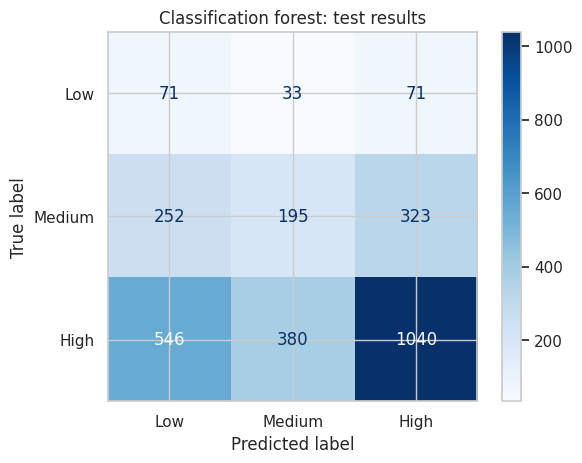

In [59]:
# Rows = actual classes. Columns = predicted classes. Diagonal = correct.
class_predictions = best_classifier.predict(X_test)
print(classification_report(y_test_class, class_predictions,
                            labels=["Low", "Medium", "High"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test_class, class_predictions,
    labels=["Low", "Medium", "High"], cmap="Blues")
plt.title(classifier_name + ": test results")
plt.show()


In [60]:
# Compare examples the classifier gets wrong with examples it gets right.
class_examples = model_df.loc[X_test.index, ["name", "ingredients", "total_ratings"]].copy()
class_examples["Actual class"] = y_test_class
class_examples["Predicted class"] = class_predictions
wrong = class_examples["Actual class"] != class_examples["Predicted class"]
print("Incorrect examples:")
display(class_examples[wrong].head(5))
print("Correct examples:")
display(class_examples[~wrong].head(5))


Incorrect examples:


,name,ingredients,total_ratings,Actual class,Predicted class
14283,Lancaster Lefsa (Old World Recipe),"3 cups mashed potatoes, ¼ cup shortening, 3 ta...",2.0,High,Low
11438,Pineapple Crisp,"2 (20 ounce) cans crushed pineapple, well drai...",185.0,High,Low
2677,Bacon Dill Pickle Pizzas,"2 naan breads, 2 teaspoons olive oil, or as ne...",1.0,Low,High
4295,Delicious Egg Salad,"8 large eggs, ½ cup mayonnaise, ¼ cup chopped ...",2.0,High,Medium
11295,Indian Rice Pilaf,"¼ cup water, 1 (14.5 ounce) can chicken broth,...",33.0,Medium,Low


Correct examples:


,name,ingredients,total_ratings,Actual class,Predicted class
2021,Healthier Monkey Bread I,"⅓ cup white sugar, 2 teaspoons ground cinnamon...",4.0,High,High
1984,Hot Artichoke Dip with Green Chiles,"½ (16 ounce) jar creamy salad dressing, 1 clov...",10.0,Medium,Medium
7110,Quick Thousand Island Dressing,"1 cup mayonnaise, ¼ cup ketchup, ¼ cup sweet p...",32.0,High,High
8629,Watermelon Pink Lemonade,"1 cup water, 2 tablespoons lemon juice, 4 teas...",8.0,High,High
3488,Jalapeño Cream Cheese Chicken Enchiladas,"3 skinless, boneless chicken breasts, 3 ½ teas...",567.0,High,High


## 22. Write your project conclusion
Fill in these sentences using **this notebook's results**:

1. **Question:** We tested whether ingredients predict average recipe ratings.
2. **Process:** We encoded ingredient text, compared a regression tree and forest, and tuned depth and leaf size through three-fold cross-validation.
3. **Baseline:** The mean baseline's test RMSE was ___. The tree's was ___ and the forest's was ___. The best model improved RMSE by ___%.
4. **Fit:** The train/CV comparison suggests ___ because ___. A small gap alone does not establish a useful model.
5. **Errors:** The hardest recipes were ___. A specific example was ___. Our response would be ___; subgroup evidence is limited by ___.
6. **Classification:** The selected classifier's balanced accuracy was ___ versus ___ for the dummy. Its ordinary accuracy was ___. These metrics are not interchangeable.
7. **Decision:** Under our assumed values, the frozen promotion policy scored ___ versus ___ for everyone and ___ for no one. These are hypothetical values, not real profits.
8. **Recommendation:** We would choose ___ among the two methods because ___. We would / would not deploy it because its gain over a simple baseline is ___.

**A weak result is valid.** If ingredient-based models barely beat the baseline, conclude that this representation of ingredients contains limited predictive information. Do not promise that more trees or a more complicated model will necessarily fix it.

### How this differs from the longer notebook
- Uses the lab's direct fit, predict, plot, and grid-search pattern.
- Adds an easy-to-read full tree versus reduced tree example and a new-recipe prediction.
- Removes custom functions, automatic range-expansion loops, bootstrap intervals, tuning heatmaps, and file-export code.
- Keeps the evaluation requirements in short, clearly labeled cells.
- Uses fixed grid ranges and 50 trees for both forests. Check upper boundaries manually.
- Uses default three-fold splits in GridSearchCV, so the CV fold assignments differ from the previous shuffled-fold implementation. The outer train/test split stays at 80/20 with seed 42.

**Sources:** Your BA305 Decision Trees slides and the linked loan-acceptance lab. Extra text preprocessing is needed because this dataset contains ingredient strings rather than the lab's numeric customer columns.